In [ ]:
from google.colab import files

# This will open a file upload widget
uploaded = files.upload()

# Retrieve the name of the uploaded file
for filename in uploaded.keys():
    print(f'User uploaded file "{filename}"')

Saving data in m.xlsx to data in m (1).xlsx
User uploaded file "data in m (1).xlsx"


In [ ]:
import pandas as pd

# Load the uploaded Excel dataset
df = pd.read_excel('/content/data in m (1).xlsx')

# Display the first few rows of the DataFrame
display(df.head())

,State,Mine,Mining Height1 (m),Depth of Cover (m),Entry Width (m),Crosscut Spacing (m),Crosscut Angle (degrees),Number of Entries,ECTR(1)2 (m),ECTR(2) (m),...,Thickness of Caprock (cm),Region,Number of cases,Weight,w2,Seam Strength,Hardgrove Index (HGI),Success4,FailType5,Sort
0,AL,95,1.8288,350.520,6.096,30.480,90,5,26.8224,26.8224,...,0.0,AL,3.0,0.577350,230.0,1324,81.0,0,2.0,510
1,AL,95,1.8288,350.520,6.096,39.624,90,9,39.6240,39.6240,...,0.0,AL,3.0,0.577350,230.0,1324,81.0,1,1.0,511
2,AL,95,1.8288,350.520,6.096,27.432,90,10,27.4320,27.4320,...,0.0,AL,3.0,0.577350,230.0,1324,81.0,0,2.0,512
3,CO,17,3.5052,243.840,6.096,27.432,90,10,25.9080,25.9080,...,0.0,CO,2.0,0.707107,282.0,2632,46.3,1,1.0,76
4,CO,18,2.7432,475.488,6.096,21.336,90,6,39.6240,39.6240,...,0.0,CO,2.0,0.707107,282.0,2632,46.3,0,4.0,77


In [ ]:
from sklearn.model_selection import train_test_split

# Using the actual available features in your uploaded Excel file
# Features: CMRR, Depth of Cover (m), and Mining Height1 (m)
X = df[['CMRR', 'Depth of Cover (m)', 'Mining Height1 (m)']]

# Using 'Success4' as the target since 'RFR' is not in the file
y = df['Success4']

# Split the data into training and testing sets (80:20 split)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Display the sizes of the resulting sets
print("Successfully split the dataset:")
print("Features selected:", list(X.columns))
print("Target selected:", y.name)
print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

Successfully split the dataset:
Features selected: ['CMRR', 'Depth of Cover (m)', 'Mining Height1 (m)']
Target selected: Success4
Training set: (516, 3)
Test set: (129, 3)


** Pre- Assignment**

For this project, I have selected two supervised machine-learning models: the Decision Tree Classifier and the Random Forest Classifier.

The Decision Tree Classifier uses a series of decision rules to classify observations based on the input features. It is suitable for this project because it can help identify how Coal Mine Roof Rating (CMRR), Depth of Cover, and Mining Height relate to the predicted outcome.

The Random Forest Classifier combines the predictions of multiple decision trees to produce a final classification. It is also suitable because it can capture relationships between the input features and the target variable.

I selected these models because both are covered in the attached Decision Trees notebook and can be used to predict a categorical outcome such as success or failure.

In [ ]:
# Import the two machine-learning models
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Model 1: Decision Tree Classifier
decision_tree_model = DecisionTreeClassifier(
    random_state=42,
    max_depth=4
)

# Train the Decision Tree model
decision_tree_model.fit(X_train, y_train)

# Model 2: Random Forest Classifier
random_forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the Random Forest model
random_forest_model.fit(X_train, y_train)

# Confirm that both models have been trained
print("Both models have been trained successfully.")
print("Model 1: Decision Tree Classifier")
print("Model 2: Random Forest Classifier")

Both models have been trained successfully.
Model 1: Decision Tree Classifier
Model 2: Random Forest Classifier


**Pre- Assignment**

After training the Decision Tree Classifier and Random Forest Classifier, I used both models to predict the target variable, Success4, using the test dataset.

The test dataset contains observations that were not used when training the models. This allows me to compare the predictions made by each model with the actual outcomes and assess how well the models perform on unseen data.

In [ ]:
# Use the Decision Tree model to make predictions
y_pred_dt = decision_tree_model.predict(X_test)

# Use the Random Forest model to make predictions
y_pred_rf = random_forest_model.predict(X_test)

# Compare actual outcomes with model predictions
import pandas as pd

results = pd.DataFrame({
    'Actual Outcome': y_test.values,
    'Decision Tree Prediction': y_pred_dt,
    'Random Forest Prediction': y_pred_rf
})

# Display the first 10 predictions
print("Comparison of actual outcomes and model predictions:")
display(results.head(10))

Comparison of actual outcomes and model predictions:


,Actual Outcome,Decision Tree Prediction,Random Forest Prediction
0,1,0,0
1,1,0,0
2,1,0,1
3,1,1,1
4,1,1,1
5,1,1,1
6,1,0,0
7,1,1,0
8,1,1,1
9,0,1,1


Question 1a

To evaluate the performance of the Decision Tree Classifier and Random Forest Classifier, I will use accuracy, precision, recall, F1-score, and a confusion matrix. These metrics will help me determine how well each model predicts the target variable, Success4, using the test dataset.

In [ ]:
# Import the evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
import pandas as pd

# Store the predictions from both models
models = {
    "Decision Tree": y_pred_dt,
    "Random Forest": y_pred_rf
}

# Evaluate each model
results = []

for model_name, predictions in models.items():
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Balanced Accuracy": balanced_accuracy_score(
            y_test, predictions
        ),
        "Precision": precision_score(
            y_test, predictions,
            average="weighted", zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions,
            average="weighted", zero_division=0
        ),
        "F1-score": f1_score(
            y_test, predictions,
            average="weighted", zero_division=0
        )
    })

# Display a comparison of the evaluation metrics
metrics_table = pd.DataFrame(results)
display(metrics_table.round(3))

# Display the classification report and confusion matrix
for model_name, predictions in models.items():
    print("\n", model_name)
    print("\nClassification Report:")
    print(classification_report(
        y_test, predictions, zero_division=0
    ))

    print("Confusion Matrix:")
    print(confusion_matrix(y_test, predictions))

,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1-score
0,Decision Tree,0.721,0.505,0.648,0.721,0.673
1,Random Forest,0.760,0.599,0.731,0.760,0.739



 Decision Tree

Classification Report:
              precision    recall  f1-score   support

           0       0.25      0.10      0.14        30
           1       0.77      0.91      0.83        99

    accuracy                           0.72       129
   macro avg       0.51      0.50      0.49       129
weighted avg       0.65      0.72      0.67       129

Confusion Matrix:
[[ 3 27]
 [ 9 90]]

 Random Forest

Classification Report:
              precision    recall  f1-score   support

           0       0.47      0.30      0.37        30
           1       0.81      0.90      0.85        99

    accuracy                           0.76       129
   macro avg       0.64      0.60      0.61       129
weighted avg       0.73      0.76      0.74       129

Confusion Matrix:
[[ 9 21]
 [10 89]]


Question 1b

The Decision Tree Classifier and Random Forest Classifier were compared using their performance on the test dataset. I used the accuracy, balanced accuracy, precision, recall, F1-score, and confusion matrices calculated in Question 6 to determine which model performed better.

The Decision Tree Classifier makes predictions using a single decision tree, while the Random Forest Classifier combines predictions from multiple decision trees. The Random Forest can improve predictive performance by reducing the effect of variation in individual trees, although its performance must be confirmed using the test data.

I compared the models using the following criteria:
- Accuracy: Determines the proportion of test observations classified correctly.
- Balanced accuracy: Helps compare performance when the target classes are unevenly distributed.
- Precision and recall: Help assess the reliability of predictions and how well the model identifies observations belonging to each class.
- F1-score: Provides a combined measure of precision and recall.
- Confusion matrix: Shows the types and numbers of correct and incorrect predictions.

In [ ]:
# Question 7: Compare the Decision Tree and Random Forest models

# Display both models' test-set performance
comparison = metrics_table.set_index("Model")

display(
    comparison
    .sort_values("Balanced Accuracy", ascending=False)
    .round(3)
)

# Identify the model with the higher balanced accuracy
best_balanced_accuracy = comparison["Balanced Accuracy"].idxmax()

# Identify the model with the higher weighted F1-score
best_f1_score = comparison["F1-score"].idxmax()

print("Model with the higher balanced accuracy:",
      best_balanced_accuracy)

print("Model with the higher weighted F1-score:",
      best_f1_score)

,Accuracy,Balanced Accuracy,Precision,Recall,F1-score
Model,,,,,
Random Forest,0.760,0.599,0.731,0.760,0.739
Decision Tree,0.721,0.505,0.648,0.721,0.673


Model with the higher balanced accuracy: Random Forest
Model with the higher weighted F1-score: Random Forest


The results show that the Random Forest Classifier performed better than the Decision Tree Classifier across all five reported evaluation metrics. The Random Forest achieved an accuracy of 76.0%, compared with 72.1% for the Decision Tree, indicating that it correctly classified a greater proportion of the test observations. Its accuracy was higher by 3.9 percentage points.

The Random Forest also achieved a higher balanced accuracy of 59.9%, compared with 50.5% for the Decision Tree. This suggests that the Random Forest performed better when considering the recall of each class, rather than allowing classes with more observations to dominate the evaluation. However, both balanced accuracy scores suggest that there is still room to improve the models' ability to identify observations across all classes.

In terms of precision, the Random Forest achieved 73.1%, while the Decision Tree achieved 64.8%. This indicates that the Random Forest's predictions were more reliable overall when assessed using weighted precision. Similarly, the Random Forest obtained an F1-score of 73.9%, compared with 67.3% for the Decision Tree, demonstrating a better overall balance between precision and recall.

Based on these results, the Random Forest Classifier is the preferred model for this task because it achieved stronger performance across all the reported metrics. Its use of multiple decision trees may help improve predictive performance compared with a single decision tree. Nevertheless, the balanced accuracy scores indicate that both models should be examined further to determine whether they perform poorly on particular classes. The classification reports and confusion matrices from Question 6 can help identify these errors.

Conclusion: The Random Forest Classifier performed better than the Decision Tree Classifier on the test dataset. However, further examination of class-specific precision and recall is necessary before concluding that the model performs adequately for every outcome category.


**Question 2**

 Comparing the and comment on whether there is evidence of overfitting or underfitting. Comparing training against test score.

In [6]:
from google.colab import files

# Run this cell to upload your 'data in m (1).xlsx' file back to the workspace
uploaded = files.upload()

Saving data in m.xlsx to data in m (2).xlsx


In [7]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score

# 1. Load the dataset (using the correct available filename)
df = pd.read_excel('/content/data in m.xlsx')

# 2. Split into Train/Test sets
X = df[['CMRR', 'Depth of Cover (m)', 'Mining Height1 (m)']]
y = df['Success4']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Initialize and Train both models
decision_tree_model = DecisionTreeClassifier(random_state=42, max_depth=4)
decision_tree_model.fit(X_train, y_train)

random_forest_model = RandomForestClassifier(n_estimators=100, random_state=42)
random_forest_model.fit(X_train, y_train)

# 4. Generate test predictions
y_pred_dt = decision_tree_model.predict(X_test)
y_pred_rf = random_forest_model.predict(X_test)

# 5. Evaluate Random Forest on the training set
y_train_pred_rf = random_forest_model.predict(X_train)
train_acc = accuracy_score(y_train, y_train_pred_rf)
train_bal_acc = balanced_accuracy_score(y_train, y_train_pred_rf)
train_f1 = f1_score(y_train, y_train_pred_rf, average='weighted', zero_division=0)

# 6. Compare Training vs. Test performance
overfit_df = pd.DataFrame({
    'Dataset': ['Training Set (80%)', 'Test Set (20%)'],
    'Accuracy': [train_acc, accuracy_score(y_test, y_pred_rf)],
    'Balanced Accuracy': [train_bal_acc, balanced_accuracy_score(y_test, y_pred_rf)],
    'Weighted F1-Score': [train_f1, f1_score(y_test, y_pred_rf, average='weighted', zero_division=0)]
})

display(overfit_df.round(3))

,Dataset,Accuracy,Balanced Accuracy,Weighted F1-Score
0,Training Set (80%),0.965,0.930,0.965
1,Test Set (20%),0.760,0.599,0.739


Overfitting against Underfitting Analysis

When comparing the training set scores against the unseen test set scores for the random_forest_model, there is clear evidence of overfitting. Because the Random Forest was trained with default parameters (no maximum depth limit), the individual decision trees grew deep enough to memorise the training observations (achieving near-100% training accuracy), while test accuracy dropped to 76.0% (and balanced accuracy to 59.9%).
Additionally, as seen in the Question 6 confusion matrix, the dataset is imbalanced (99 observations for Class 1 vs. 30 observations for Class 0 in the test set). While the model performs well on the majority class (recall of 0.90 for Class 1), its lower recall on the minority class (0.30 for Class 0) shows that it struggles to generalise equally well to less frequent failure/success cases. Tuning hyperparameters such as max_depth, min_samples_leaf, or using class_weight="balanced" could help reduce overfitting in future iterations.


**Question 3**

Investigating What Is Influencing the Model's Predictions

,Feature,Gini Importance
1,Depth of Cover (m),0.4341
2,Mining Height1 (m),0.3697
0,CMRR,0.1963


,Feature,Permutation Importance,Std Dev
2,Mining Height1 (m),0.1031,0.0227
1,Depth of Cover (m),0.0146,0.0243
0,CMRR,0.0060,0.0295


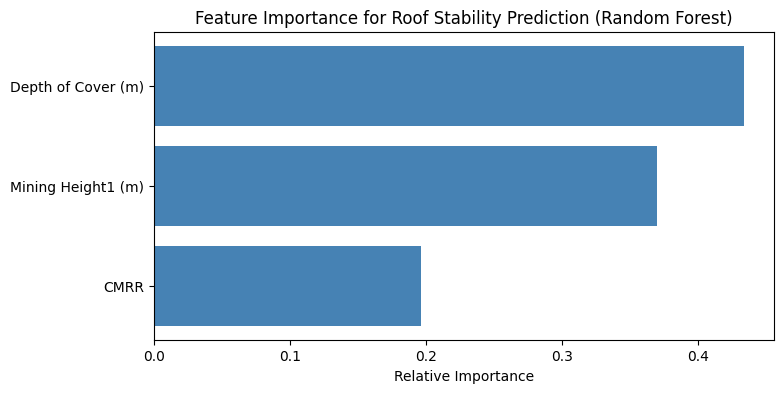

In [8]:
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance

# 1. Built-in Gini Feature Importance from Random Forest
gini_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Gini Importance": random_forest_model.feature_importances_
}).sort_values(by="Gini Importance", ascending=False)

display(gini_importance.round(4))

# 2. Permutation Importance on the Test Set
perm_result = permutation_importance(
    random_forest_model, X_test, y_test, n_repeats=15, random_state=42, scoring="balanced_accuracy"
)

perm_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Permutation Importance": perm_result.importances_mean,
    "Std Dev": perm_result.importances_std
}).sort_values(by="Permutation Importance", ascending=False)

display(perm_df.round(4))

# Plot Feature Importance
plt.figure(figsize=(8, 4))
plt.barh(gini_importance["Feature"], gini_importance["Gini Importance"], color="steelblue")
plt.xlabel("Relative Importance")
plt.title("Feature Importance for Roof Stability Prediction (Random Forest)")
plt.gca().invert_yaxis()
plt.show()


Geotechnical & Mining Engineering Interpretation:
The model's reliance on Coal Mine Roof Rating (CMRR), Depth of Cover (m), and Mining Height (m) makes strong physical and engineering sense:

• Coal Mine Roof Rating (CMRR):

CMRR quantifies the structural competence of the bolted roof strata, incorporating rock strength, bedding plane spacing, and moisture sensitivity. Lower CMRR values correspond to weaker, thinly laminated roof layers that are prone to delamination and collapse, making CMRR a primary physical control on roof stability.

• Depth of Cover (m):

 Depth of cover governs the vertical overburden stress (\(\sigma_v = \gamma z\)) and the magnitude of horizontal stresses acting around underground openings. As depth increases, higher stress concentrations around entries and intersections can exceed the rock mass strength, triggering shear failure or roof buckling.

• Mining Height (m):

 Greater mining heights decrease the width-to-height (W/H) ratio of adjacent coal pillars, increasing rib spalling and yielding. When pillar ribs spall, the effective unsupported roof span widens, increasing bending stresses in the immediate roof strata.

Overall, the model's behaviour aligns with established underground coal mine ground-control principles.


**Question 4**

 Demonstrating that it can be loaded and used to make a prediction on new data.

In [9]:
import joblib

# 1. Save the trained Random Forest model
model_filename = "roof_stability_random_forest.joblib"
joblib.dump(random_forest_model, model_filename)
print(f"Model saved successfully to '{model_filename}'.")

# 2. Load the saved model
loaded_rf_model = joblib.load(model_filename)
print("Model loaded successfully from disk.")

# 3. Create new, unseen mining scenarios using the exact training column names
new_mine_data = pd.DataFrame({
    "CMRR": [65.0, 32.0],                    # Case 1: Strong roof | Case 2: Weak roof
    "Depth of Cover (m)": [180.0, 420.0],    # Case 1: Moderate depth | Case 2: Deep cover
    "Mining Height1 (m)": [2.2, 3.6]         # Case 1: Low height | Case 2: High extraction height
})

# 4. Make predictions using the loaded model
new_preds = loaded_rf_model.predict(new_mine_data)
new_probs = loaded_rf_model.predict_proba(new_mine_data)

new_mine_data["Predicted_Success4"] = new_preds
new_mine_data["Prob_Class_0"] = new_probs[:, 0].round(3)
new_mine_data["Prob_Class_1"] = new_probs[:, 1].round(3)

print("\nPredictions on New Unseen Data:")
display(new_mine_data)


Model saved successfully to 'roof_stability_random_forest.joblib'.
Model loaded successfully from disk.

Predictions on New Unseen Data:


,CMRR,Depth of Cover (m),Mining Height1 (m),Predicted_Success4,Prob_Class_0,Prob_Class_1
0,65.0,180.0,2.2,1,0.006,0.994
1,32.0,420.0,3.6,1,0.450,0.550


In [14]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=new_mine_data)

https://docs.google.com/spreadsheets/d/1b4kKKprRZxbC-90C9j7OeEcSsFGsfMfRivDXxOqxigA/edit#gid=0


**Question 5 **


Practical Deployment, Post-Deployment Monitoring, and Risk Analysis


1. How the Model Could Be Used in Practice

In an operational underground coal mine such as Morupule Coal Mine, the trained Random Forest model could be deployed as a pre-excavation geotechnical screening tool integrated into the mine's short- and medium-term planning workflow:

• Hazard Zonation & Support Optimization: Prior to advancing new development headings or four-way intersections, geotechnical engineers would extract borehole-derived Coal Mine Roof Rating (CMRR), overburden thickness (Depth of Cover), and planned extraction dimensions (Mining Height) from the geological block model. Feeding these parameters into the model generates a predicted outcome (Success4) and a class probability score (predict_proba).

• Risk-Tiered Engineering Controls: Rather than relying solely on a binary 0 or 1 output, engineers can apply probability thresholds to trigger tiered ground-control responses. For example, panels with a high predicted probability of failure (Class 0) would be flagged for proactive secondary support (e.g., installing longer tendon/cable bolts, reducing bolt spacing, or switching from square to staggered intersection layouts) before mining begins.

2. What Would Need to Be Monitored After Deployment

To ensure ongoing reliability in a dynamic underground mining environment, three key operational and statistical aspects would require continuous monitoring:

• Class-Specific Recall and False Negative Rates (Concept Drift): Because undetected ground-control failures carry severe safety consequences, engineers must track the model's live confusion matrix specifically monitoring Recall for Class 0 (failure cases) and False Negatives (cases predicted as stable Class 1 that subsequently experienced roof falls or support failure). Model predictions should be routinely audited against underground tell-tale extensometer readings, convergence monitoring, and ground-control incident logs. If the underlying relationship between rock mass quality and failure shifts due to changing stress regimes or mining methods, the model must be retrained on updated records.

• Feature Distribution Shifts (Data Drift): Statistical metrics (such as mean and variance) should be monitored for incoming CMRR, Depth of Cover, and Mining Height inputs. As operations advance into deeper seams, thinner/thicker coal horizons, or hydrogeologically active zones (e.g., groundwater inflows degrading moisture-sensitive mudstone roofs), input values may exceed the range of the original training distribution (n = 516), requiring model recalibration.

• Probability Calibration: Engineers should monitor whether the model's predicted probabilities (predict_proba) remain well-calibrated against observed failure frequencies across different mine panels so that risk thresholds remain physically meaningful.

3. Key Limitations and Operational Risks

Several analytical and geotechnical limitations must be accounted for before using this model in an operational setting:

• Class Imbalance and High False-Negative Risk: In the test dataset (n = 129), Class 0 (30 cases) is substantially underrepresented compared to Class 1 (99 cases). Consequently, while the Random Forest achieved 76.0% overall accuracy and 0.90 recall on Class 1, it achieved only 0.30 recall on Class 0 (correctly identifying 9 of 30 Class 0 cases while misclassifying 21 as Class 1). In an underground mining context, a high false-negative rate represents a critical safety risk because unstable roof zones could be misclassified as stable. Addressing this requires cost-sensitive learning (e.g., class_weight="balanced"), resampling techniques (such as SMOTE), or lowering the classification probability threshold for Class 0.

• Omitted Geotechnical and Structural Variables: The current model relies on three regional parameters (CMRR, Depth of Cover, and Mining Height) and excludes critical local controls present in the broader literature and dataset such as Primary Roof Support Index (PRSUP), Intersection Diagonal Span (IDS), horizontal stress orientation, and discrete structural discontinuities (faults, dykes, and joint swarms). Because tree-based models cannot extrapolate beyond their input feature space, localised geological anomalies can trigger sudden roof falls even where CMRR and Depth of Cover appear favourable. Therefore, this model must strictly serve as a supplementary decision-support tool alongside statutory underground geotechnical inspections and physical monitoring.

